# Stage 4a: light users without retraining (Cor. 2, plan Step G items 1–4), Enron, GPT-Neo 125M
**Plan:** section 4 row 4, first part. Post-processing of Stage 2 (10 main seeds); no GPU. Cap retraining (Step G.6) is Stage 4b, not decided yet.

Per seed, m, draw and statistic: threshold = 95% quantile of the statistic among non-member users (FPR γ = 5%); a member is
detected if above it. Members are binned by k_u (training docs) and α_u (share of the training set).
**Cor. 2 prediction:** T̂ stays near chance (TPR ≈ γ) for light users at any m.

**Caveat:** after the 150+32 filter every Enron user has k_u ≥ 114, so there are no truly light users here; this stage compares
lighter with heavier users. With ~90 non-members, the 5% threshold rests on the top ~4–5 non-members, so per-seed TPRs are noisy.

In [1]:
import os, sys, numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.path.abspath("."))
import analysis as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_rows", 200)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25})
# categorical slots 1-3 (same as Stage 2); ordered groups use one blue ramp, light -> dark
COL = {"T": "#2a78d6", "S_cat": "#eb6834", "Agg": "#1baf7a"}
MRK = {"T": "o", "S_cat": "s", "Agg": "^"}
NAME = {"T": "T̂ (mean)", "S_cat": "S_cat", "Agg": "aggregator (EVAL)"}
RAMP = ["#a9cdf2", "#6aa6e8", "#2a78d6", "#174a8c"]
uv = A.S2.cached_user_values()   # Stage 2 per-user statistics (cached in Stage2/results/_user_values.csv.gz)
print(uv.groupby("run").seed.nunique().to_dict(), "models;", uv.user.nunique(), "users")

{'main': 10, 'null': 1} models; 175 users


In [2]:
det = A.member_detection(uv)
ek = A.k_bins(uv); ea = np.quantile(det.alpha_u, [0, .25, .5, .75, 1])
print("k_u bin edges:", ek.round(0), " alpha_u bin edges:", ea.round(4))
tk = A.tpr_by_bin(det, ek); ta = A.tpr_by_bin(det, ea, by="alpha_u")
display(tk.pivot_table(index="m", columns=["stat", "bin"], values="tpr", observed=True).round(3))

k_u bin edges: [ 114.  164.  294.  566. 3925.]  alpha_u bin edges: [0.0021 0.0038 0.0065 0.0122 0.0968]


stat              Agg                                                          S_cat                                                              T                                              
bin  (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0] (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0] (113.999, 163.5] (163.5, 294.0] (294.0, 565.5] (565.5, 3925.0]
m                                                                                                                                                                                                
1               0.240          0.205          0.314           0.331            0.317          0.258          0.277           0.268            0.317          0.258          0.277           0.268
2               0.319          0.254          0.384           0.444            0.327          0.320          0.362           0.379            0.328          0.310          0.346           0.368
4               0.254          0.294          0.396           0.379            0.367          0.394          0.405           0.380            0.358          0.390          0.405           0.377
8               0.300          0.292          0.389           0.406            0.382          0.376          0.435           0.382            0.383          0.374          0.392           0.342
16              0.411          0.349          0.422           0.417            0.507          0.401          0.456           0.419            0.483          0.399          0.437           0.380
32              0.366          0.340          0.395           0.452            0.512          0.397          0.463           0.451            0.431          0.367          0.403           0.360

## 1. TPR at 5% FPR vs m, by k_u quartile
Line: mean over seeds; dotted: chance (γ = 0.05).

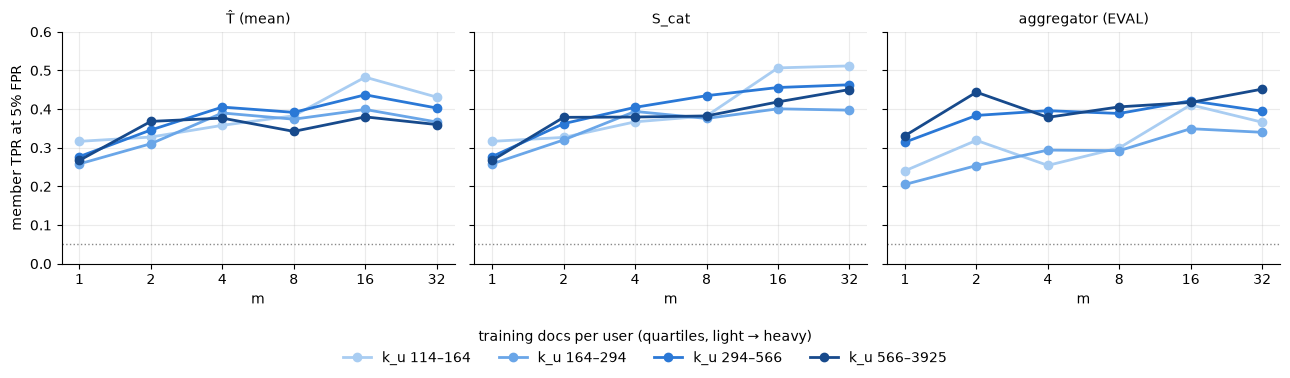

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, st in zip(axes, A.STATS):
    x = tk[tk.stat == st]
    for i, (b, g) in enumerate(x.groupby("bin", observed=True)):
        ax.plot(g.m, g.tpr, marker="o", color=RAMP[i], lw=2, ms=6, label=f"k_u {b.left:.0f}–{b.right:.0f}")
    ax.axhline(A.GAMMA, color="#888", lw=1, ls=":")
    ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32]); ax.set_xlabel("m")
    ax.set_title(NAME[st], fontsize=10)
axes[0].set_ylabel("member TPR at 5% FPR"); axes[0].set_ylim(0, 0.6)
hs, ls = axes[0].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=4, title="training docs per user (quartiles, light → heavy)")
plt.tight_layout(rect=(0, 0.14, 1, 1)); plt.show()

## 2. By α_u (share of the training set) and rank correlations

In [4]:
display(ta[ta.m.isin([1, 8, 32])].round(3))
display(A.rank_corr(det).round(3))

,stat,m,bin,tpr,tpr_min,tpr_max,members_per_seed
0,Agg,1,"(0.0010799999999999998, 0.0038]",0.224,0.077,0.375,10.0
1,Agg,1,"(0.0038, 0.00647]",0.232,0.068,0.432,11.8
2,Agg,1,"(0.00647, 0.0122]",0.302,0.234,0.364,12.9
3,Agg,1,"(0.0122, 0.0968]",0.340,0.156,0.464,9.1
12,Agg,8,"(0.0010799999999999998, 0.0038]",0.289,0.150,0.500,10.0
13,Agg,8,"(0.0038, 0.00647]",0.308,0.159,0.455,11.8
14,Agg,8,"(0.00647, 0.0122]",0.380,0.273,0.500,12.9
15,Agg,8,"(0.0122, 0.0968]",0.404,0.200,0.636,9.1
20,Agg,32,"(0.0010799999999999998, 0.0038]",0.375,0.133,0.600,10.0
21,Agg,32,"(0.0038, 0.00647]",0.362,0.091,0.556,11.8


,stat,m,rho_k_u,rho_alpha_u,rho_k_u_min,rho_k_u_max
0,Agg,1,0.131,0.131,-0.175,0.459
1,Agg,2,0.196,0.196,0.027,0.464
2,Agg,4,0.184,0.184,0.015,0.352
3,Agg,8,0.152,0.152,-0.045,0.400
4,Agg,16,0.118,0.118,-0.047,0.295
5,Agg,32,0.106,0.106,-0.028,0.253
6,S_cat,1,-0.006,-0.006,-0.148,0.242
7,S_cat,2,0.051,0.051,-0.113,0.217
8,S_cat,4,0.016,0.016,-0.130,0.184
9,S_cat,8,0.005,0.005,-0.079,0.103


## Notes (2026-11-25)
- **TPR vs k_u / α_u:** no dependence. T̂ at m = 32: TPR at 5% FPR 0.43 / 0.37 / 0.40 / 0.36 from the lightest to the heaviest k_u quartile (k_u 114–164 … 566–3925); Spearman(k_u, T̂) among members ≈ −0.02 (range −0.09 to 0.09 over seeds); same for α_u. S_cat: same picture. The aggregator alone shows a weak trend (ρ ≈ 0.1–0.2; lighter quartiles 0.34–0.37 vs 0.40–0.45 at m = 32).
- **Cor. 2 prediction (light users near chance for T̂):** not testable here. Every Enron user has k_u ≥ 114 (α_u ≥ 0.2%), and over that range lighter users are as detectable as heavy ones (TPR ≈ 0.3–0.5 ≫ γ = 0.05). Light users only exist with caps.
- **Decision:** Stage 4b (cap retraining) is needed to test Cor. 2; cap grid and seeds to be decided with the user.

# 4b: cap retraining (Kaggle, 2026-11-26), plan Step G.6
40 models: caps c ∈ {10, 25, 50, 100} train docs per member × seeds 0–9, same members as Stage 2. Stage 2's uncapped main run is the
c = ∞ point (shown as "∞"), so every comparison is paired by seed and user. Same 32 held-out docs and m-doc subsets as Stage 2. No S_cat.
CIs: user bootstrap (B = 1000), one resample shared by every cap, seed, m and draw; the aggregator is held fixed given its FIT fit.

**Checks done on load:** member labels identical to Stage 2 for every seed; every member has k_u = c; recomputing Stage 2's seed 0
through this code path gives identical T̂ (max diff 0) and aggregator (1.8e-14).

In [5]:
uvc = A.cap_user_values()
uva = A.with_uncapped(uvc, uv)
per = A.cap_metrics(uva); cs = A.cap_summary(per)
bs = A.paired_cap_bootstrap(uva, B=1000)
h = A.load_cap_histories(); h["val_gap"] = h.val_out - h.val_in
display(h.groupby("cap")[["best_epoch", "n_train_docs", "val_in", "val_out", "val_gap"]].mean().round(3))
print("member alpha_u by cap (m = 32):"); display(uva[(uva.m == 32) & (uva.b == 1)].groupby("cap").alpha_u.describe()[["min", "50%", "max"]].round(4))

,best_epoch,n_train_docs,val_in,val_out,val_gap
cap,,,,,
10,2.2,852.0,2.986,3.340,0.354
25,2.0,2130.0,2.882,3.340,0.458
50,2.3,4260.0,2.788,3.341,0.554
100,2.3,8520.0,2.688,3.323,0.636


member alpha_u by cap (m = 32):


,min,50%,max
cap,,,
10,0.0100,0.0118,0.0143
25,0.0100,0.0118,0.0143
50,0.0100,0.0118,0.0143
100,0.0100,0.0118,0.0143
1000000,0.0021,0.0064,0.0968


## 4b.1 AUROC vs m, by cap
Line: mean over seeds. Light → dark = small → large cap; grey = uncapped (Stage 2).

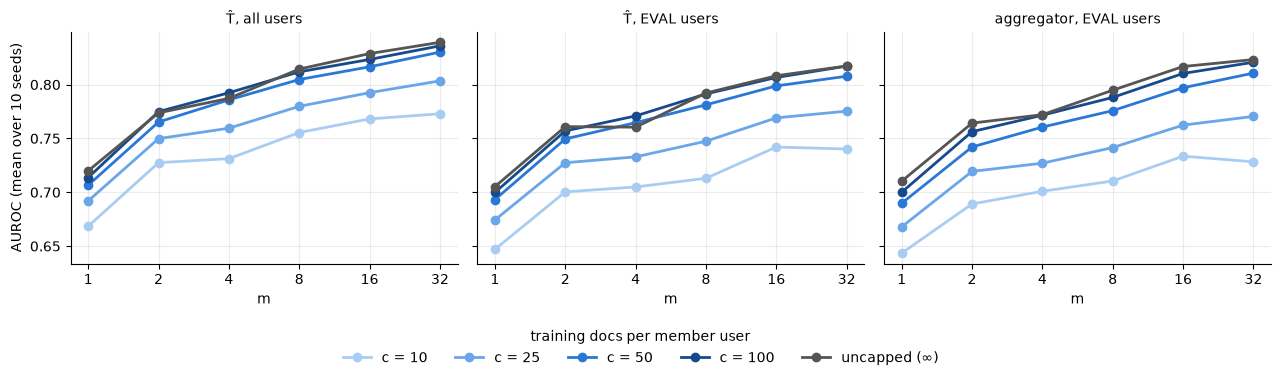

In [6]:
CAPCOL = dict(zip(A.CAPS, RAMP)); CAPCOL[A.INF] = "#555555"
CAPLAB = {c: f"c = {c}" for c in A.CAPS}; CAPLAB[A.INF] = "uncapped (∞)"
panels = [("T", "all", "T̂, all users"), ("T", "EVAL", "T̂, EVAL users"), ("Agg", "EVAL", "aggregator, EVAL users")]
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (st, grp, ttl) in zip(axes, panels):
    x = cs[(cs.stat == st) & (cs.users == grp)]
    for c in list(A.CAPS) + [A.INF]:
        g = x[x.cap == c]
        ax.plot(g.m, g.auroc, marker="o", color=CAPCOL[c], lw=2, ms=6, label=CAPLAB[c])
    ax.set_xscale("log", base=2); ax.set_xticks([1, 2, 4, 8, 16, 32], [1, 2, 4, 8, 16, 32]); ax.set_xlabel("m"); ax.set_title(ttl, fontsize=10)
axes[0].set_ylabel("AUROC (mean over 10 seeds)")
hs, ls = axes[0].get_legend_handles_labels()
fig.legend(hs, ls, frameon=False, loc="lower center", ncol=5, title="training docs per member user")
plt.tight_layout(rect=(0, 0.14, 1, 1)); plt.show()

## 4b.2 Cost of the cap and statistic dependence (m = 32, 95% user-bootstrap CIs)
Left: AUROC(c) − AUROC(uncapped), paired. Right: aggregator − T̂ at the same cap (EVAL users). Dotted: 0.

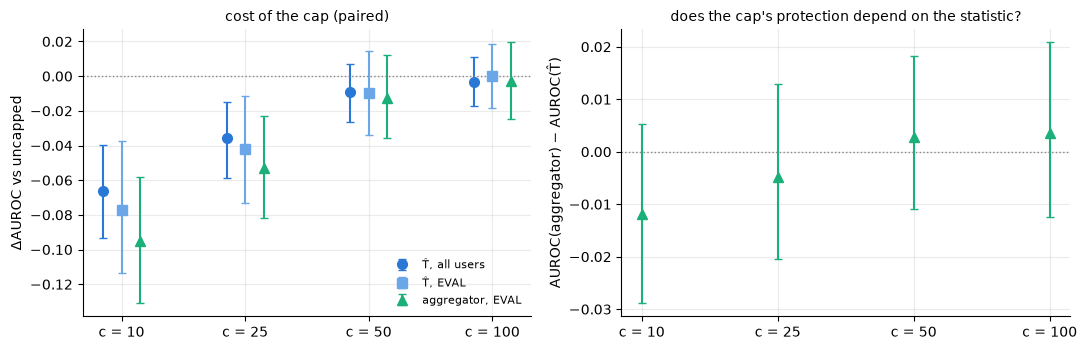

,stat,users,cap,auroc,auroc_lo,auroc_hi,d_uncapped,d_uncapped_lo,d_uncapped_hi,agg_minus_T,agg_minus_T_lo,agg_minus_T_hi
25,Agg,EVAL,10,0.728,0.682,0.779,-0.095,-0.131,-0.058,-0.012,-0.029,0.005
26,Agg,EVAL,25,0.770,0.723,0.815,-0.053,-0.082,-0.023,-0.005,-0.020,0.013
27,Agg,EVAL,50,0.811,0.769,0.850,-0.013,-0.036,0.012,0.003,-0.011,0.018
28,Agg,EVAL,100,0.821,0.780,0.860,-0.003,-0.025,0.019,0.004,-0.012,0.021
29,Agg,EVAL,1000000,0.823,0.779,0.860,0.000,0.000,0.000,0.006,-0.016,0.028
55,T,EVAL,10,0.740,0.692,0.790,-0.077,-0.114,-0.037,NaN,NaN,NaN
56,T,EVAL,25,0.775,0.727,0.820,-0.042,-0.073,-0.011,NaN,NaN,NaN
57,T,EVAL,50,0.808,0.762,0.849,-0.010,-0.034,0.015,NaN,NaN,NaN
58,T,EVAL,100,0.817,0.771,0.858,-0.000,-0.018,0.018,NaN,NaN,NaN
59,T,EVAL,1000000,0.817,0.772,0.860,0.000,0.000,0.000,NaN,NaN,NaN


In [7]:
b = bs[bs.m == 32]; xs = {c: i for i, c in enumerate(A.CAPS)}
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for j, (st, grp, lab, col, mk) in enumerate([("T", "all", "T̂, all users", COL["T"], "o"), ("T", "EVAL", "T̂, EVAL", "#6aa6e8", "s"),
                                              ("Agg", "EVAL", "aggregator, EVAL", COL["Agg"], "^")]):
    g = b[(b.stat == st) & (b.users == grp) & (b.cap != A.INF)]
    xx = np.array([xs[c] for c in g.cap]) + (j - 1) * 0.15
    axes[0].errorbar(xx, g.d_uncapped, yerr=[g.d_uncapped - g.d_uncapped_lo, g.d_uncapped_hi - g.d_uncapped], fmt=mk, color=col,
                     ms=7, lw=1.5, capsize=3, label=lab)
g = b[(b.stat == "Agg") & (b.cap != A.INF)]
axes[1].errorbar([xs[c] for c in g.cap], g.agg_minus_T, yerr=[g.agg_minus_T - g.agg_minus_T_lo, g.agg_minus_T_hi - g.agg_minus_T],
                 fmt="^", color=COL["Agg"], ms=7, lw=1.5, capsize=3)
for ax in axes:
    ax.axhline(0, color="#888", lw=1, ls=":"); ax.set_xticks(range(len(A.CAPS)), [f"c = {c}" for c in A.CAPS])
axes[0].set_ylabel("ΔAUROC vs uncapped"); axes[0].set_title("cost of the cap (paired)", fontsize=10); axes[0].legend(frameon=False, fontsize=8)
axes[1].set_ylabel("AUROC(aggregator) − AUROC(T̂)"); axes[1].set_title("does the cap's protection depend on the statistic?", fontsize=10)
plt.tight_layout(); plt.show()
display(b[["stat", "users", "cap", "auroc", "auroc_lo", "auroc_hi", "d_uncapped", "d_uncapped_lo", "d_uncapped_hi",
           "agg_minus_T", "agg_minus_T_lo", "agg_minus_T_hi"]].round(3))

## 4b.3 Certificates and TPR at 5% FPR vs cap (mean over seeds)

In [8]:
for v in ["dkw_cert", "tpr@0.05"]:
    print(v); display(cs.pivot_table(index=["stat", "users", "m"], columns="cap", values=v).loc[(slice(None), slice(None), [1, 8, 32]), :].round(3))

dkw_cert


cap            10       25       50       100      1000000
stat users m                                              
Agg  EVAL  1    -0.158   -0.119   -0.103   -0.086   -0.078
           8    -0.073   -0.029    0.017    0.038    0.052
           32   -0.034    0.001    0.064    0.078    0.102
T    EVAL  1    -0.154   -0.110   -0.100   -0.088   -0.084
           8    -0.056   -0.018    0.032    0.044    0.054
           32   -0.028    0.028    0.074    0.074    0.099
     all   1    -0.031   -0.002    0.013    0.027    0.040
           8     0.099    0.131    0.175    0.186    0.197
           32    0.121    0.162    0.214    0.211    0.228

tpr@0.05


cap            10       25       50       100      1000000
stat users m                                              
Agg  EVAL  1     0.242    0.255    0.268    0.287    0.275
           8     0.335    0.362    0.402    0.406    0.347
           32    0.339    0.370    0.459    0.460    0.385
T    EVAL  1     0.234    0.249    0.274    0.284    0.274
           8     0.349    0.383    0.410    0.407    0.353
           32    0.369    0.399    0.463    0.451    0.380
     all   1     0.253    0.275    0.284    0.295    0.280
           8     0.369    0.380    0.413    0.417    0.372
           32    0.380    0.435    0.483    0.467    0.390

## 4b Notes (2026-11-27)
- **Training:** best epoch 2–3 at every cap. Member validation loss improves even at c = 10 (3.36 → 2.99), while non-member validation loss barely moves (3.44 → 3.34).
  The model learns user-level style and topics from 10 docs.
- **Cost of the cap:** small, and only below about 50 docs. T̂ (all users, m = 32): 0.839 uncapped, 0.836 at c = 100, 0.830 at c = 50, 0.803 at c = 25, 0.773 at c = 10.
  Paired Δ at c = 10 is −0.066 [−0.093, −0.040]; at c ≥ 50 the CI contains 0. The c = 10 DKW certificate is still positive (0.12 vs 0.23 uncapped).
- **Statistic dependence (Step G.6):** none in practice. |Aggregator − T̂| ≤ 0.012 at every cap and m. 2 of 30 CIs exclude 0, in opposite directions (c = 10, m = 2: −0.011; uncapped, m = 4: +0.012, Stage 2's known result). The cap protects against both equally, and little.
- **Cor. 2 is not tested by uniform caps.** A uniform cap gives every member the same share α_u = 1/(members) ≈ 0.012. That is larger than the uncapped median (0.006),
  so capped users are not light in Cor. 2's α_u sense. 4a already covered α_u down to 0.002 (TPR flat).
- **Falsifier (Stage 4):** "user-level statistics also fail on light users". Neither statistic fails: T̂ is far above chance at c = 10 (AUROC 0.77, TPR@5% ≈ 0.38).
  Cor. 2's contrast (T̂ blind to light users, user-level statistics not) is **not supported** in any regime reached so far.
- **Open:** a real test needs small α_u: cap only some members (e.g. half capped at c = 10, the others uncapped, α_u ≈ 3·10⁻⁴). Not run; to discuss.